# 03 — Univariate Forecasting
Forecast the selected lithium carbonate price using only its own past values. This provides the baseline against which multivariate models will be compared.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_FILE = Path("../data/lithium_consolidated_monthly.csv")
TARGET = "Selected lithium carbonate price (CNY/t)"
JAPAN_INDEX = "Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100"
RANDOM_STATE = 42

df = pd.read_csv(DATA_FILE)
df["Month"] = pd.to_datetime(df["Month"])
df = df.sort_values("Month").drop_duplicates("Month").set_index("Month").asfreq("MS")
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

EXCLUDED = {
    TARGET, "Selected target source",
    "Lithium carbonate price (CNY/metric tonne)",
    "China spot lithium carbonate price (CNY/t) - CSV",
    "OLD - faulty cobalt settlement series (constant; excluded)",
    "China spot price open (CNY/t) - CSV",
    "China spot price high (CNY/t) - CSV",
    "China spot price low (CNY/t) - CSV",
    "China spot price volume (CSV)",
    "China spot price change (%) - CSV",
}
ALL_PREDICTORS = [c for c in df.select_dtypes(include=np.number).columns if c not in EXCLUDED]

def make_supervised(horizon=1, n_lags=6, exog_cols=None):
    """At month t, use target/predictor observations through t to predict target at t+h."""
    X = pd.DataFrame(index=df.index)
    for lag in range(0, n_lags):
        X[f"target_lag_{lag}"] = df[TARGET].shift(lag)
    if exog_cols:
        for col in exog_cols:
            for lag in range(1, n_lags + 1):
                X[f"{col}_lag_{lag}"] = pd.to_numeric(df[col], errors="coerce").shift(lag)
    y = df[TARGET].shift(-horizon).rename("target")
    data = X.join(y).dropna(subset=["target"])
    # Do not require every optional predictor to be present. Missing features are imputed within each training fold.
    return data.drop(columns="target"), data["target"]

def split_time(X, y, test_fraction=0.2):
    split = int(len(X) * (1-test_fraction))
    return X.iloc[:split], X.iloc[split:], y.iloc[:split], y.iloc[split:]

def model_bank():
    return {
        "Linear Regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression()),
        "Ridge": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10)),
        "KNN": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), KNeighborsRegressor(n_neighbors=5)),
        "SVR": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), SVR(C=10, epsilon=0.1)),
        "Random Forest": make_pipeline(SimpleImputer(strategy="median"), RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE)),
        "Gradient Boosting": make_pipeline(SimpleImputer(strategy="median"), GradientBoostingRegressor(random_state=RANDOM_STATE)),
    }

def score_predictions(y_true, pred):
    return {"MAE": mean_absolute_error(y_true, pred),
            "RMSE": mean_squared_error(y_true, pred)**0.5,
            "R2": r2_score(y_true, pred)}

## 1. Forecast horizons and model benchmark

In [2]:
HORIZONS = [1, 3, 6, 12]
results, predictions = [], {}
for h in HORIZONS:
    X, y = make_supervised(horizon=h, n_lags=12, exog_cols=None)
    X_train, X_test, y_train, y_test = split_time(X, y)
    for name, model in model_bank().items():
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        row = {"Horizon (months)": h, "Model": name, **score_predictions(y_test, pred)}
        results.append(row)
        predictions[(h, name)] = (y_test, pred)
results = pd.DataFrame(results).sort_values(["Horizon (months)", "RMSE"])
display(results)

,Horizon (months),Model,MAE,RMSE,R2
4,1,Random Forest,19636.357420,28140.839935,0.761251
5,1,Gradient Boosting,20353.932025,29391.327073,0.739561
0,1,Linear Regression,27361.224325,43389.306135,0.432413
1,1,Ridge,37097.513685,53112.570287,0.149525
2,1,KNN,43263.488095,70710.311296,-0.507414
3,1,SVR,75148.436372,94668.260052,-1.701941
11,3,Gradient Boosting,48434.612614,76679.145576,-0.772644
10,3,Random Forest,53846.622876,88257.838958,-1.348408
7,3,Ridge,67740.822302,90280.216552,-1.457266
9,3,SVR,74733.637517,94354.195869,-1.684043


## 2. Best model by horizon

In [3]:
best = results.loc[results.groupby("Horizon (months)")["RMSE"].idxmin()].sort_values("Horizon (months)")
display(best)

,Horizon (months),Model,MAE,RMSE,R2
4,1,Random Forest,19636.357420,28140.839935,0.761251
11,3,Gradient Boosting,48434.612614,76679.145576,-0.772644
17,6,Gradient Boosting,62236.752527,80219.848690,-1.076572
20,12,KNN,46902.900000,63489.862135,-0.714772


## 3. Plot one-month-ahead predictions

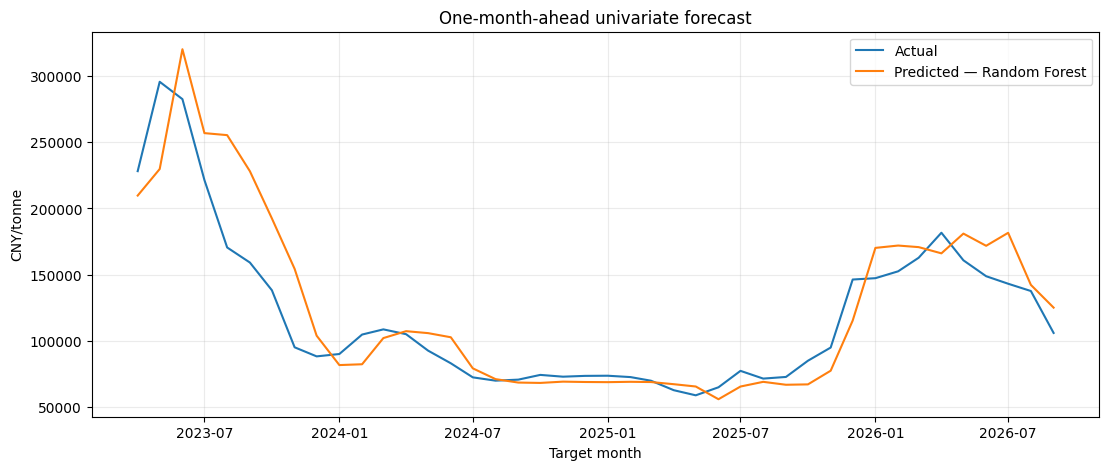

In [4]:
h=1
best_name = best.loc[best["Horizon (months)"]==h, "Model"].iloc[0]
y_test, pred = predictions[(h, best_name)]
fig, ax = plt.subplots(figsize=(13,5))
ax.plot(y_test.index, y_test.values, label="Actual")
ax.plot(y_test.index, pred, label=f"Predicted — {best_name}")
ax.set(title="One-month-ahead univariate forecast", xlabel="Target month", ylabel="CNY/tonne")
ax.legend(); ax.grid(alpha=.25); plt.show()

## 4. Save results

In [5]:
results.to_csv("../results/univariate_model_comparison.csv", index=False)
print("Saved ../results/univariate_model_comparison.csv")

Saved ../results/univariate_model_comparison.csv


## Interpretation notes
- The test set is the final chronological 20% of supervised observations.
- Imputation is fitted only on training data through the pipeline.
- For horizon h, predictors are lagged observations and the target is shifted h months ahead.
- A random train/test split is inappropriate for this time-series forecasting task.